In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/cafethai_prices.csv', parse_dates=['date'], date_format='%d/%m/%Y')
display(df.head())

,date,time,cash_type,coffee_name,money
0,2023-03-01,08:04:19,card,Latte,75
1,2023-03-01,08:08:54,cash,Americano with Milk,70
2,2023-03-01,08:09:03,card,Cappuccino,75
3,2023-03-01,08:10:26,cash,Cappuccino,75
4,2023-03-01,08:15:37,cash,Cappuccino,75


In [5]:
df.set_index('date', inplace=True)

df.head()

,time,cash_type,coffee_name,money
date,,,,
2023-03-01,08:04:19,card,Latte,75
2023-03-01,08:08:54,cash,Americano with Milk,70
2023-03-01,08:09:03,card,Cappuccino,75
2023-03-01,08:10:26,cash,Cappuccino,75
2023-03-01,08:15:37,cash,Cappuccino,75


In [6]:
#รวมข้อมูลยอดขายแต่ละเมนู ในแต่ละวัน
daily_sales = df.groupby(['date', 'coffee_name'])['money'].sum().reset_index()
daily_sales.head()

,date,coffee_name,money
0,2023-03-01,Americano,1235
1,2023-03-01,Americano with Milk,1890
2,2023-03-01,Cappuccino,1800
3,2023-03-01,Cocoa,350
4,2023-03-01,Cortado,980


In [7]:
# DataFrame for the count of each coffee item sold per day
daily_item_counts = df.groupby(['date', 'coffee_name']).size().reset_index(name='count')
daily_item_counts.head()

,date,coffee_name,count
0,2023-03-01,Americano,19
1,2023-03-01,Americano with Milk,27
2,2023-03-01,Cappuccino,24
3,2023-03-01,Cocoa,7
4,2023-03-01,Cortado,14


In [8]:
# DataFrame for the total sales per day for all coffee items
daily_total_sales = df.groupby('date')['money'].sum().reset_index(name='total_sales')
daily_total_sales.head()

,date,total_sales
0,2023-03-01,8645
1,2023-03-02,8560
2,2023-03-03,8690
3,2023-03-04,4365
4,2023-03-05,4565


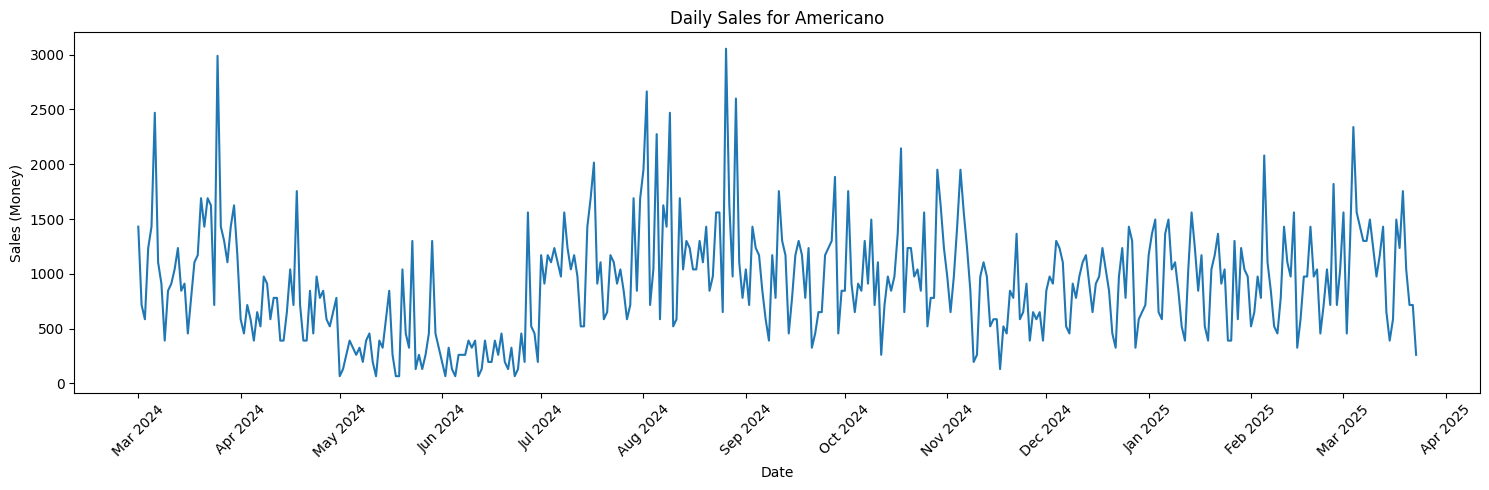

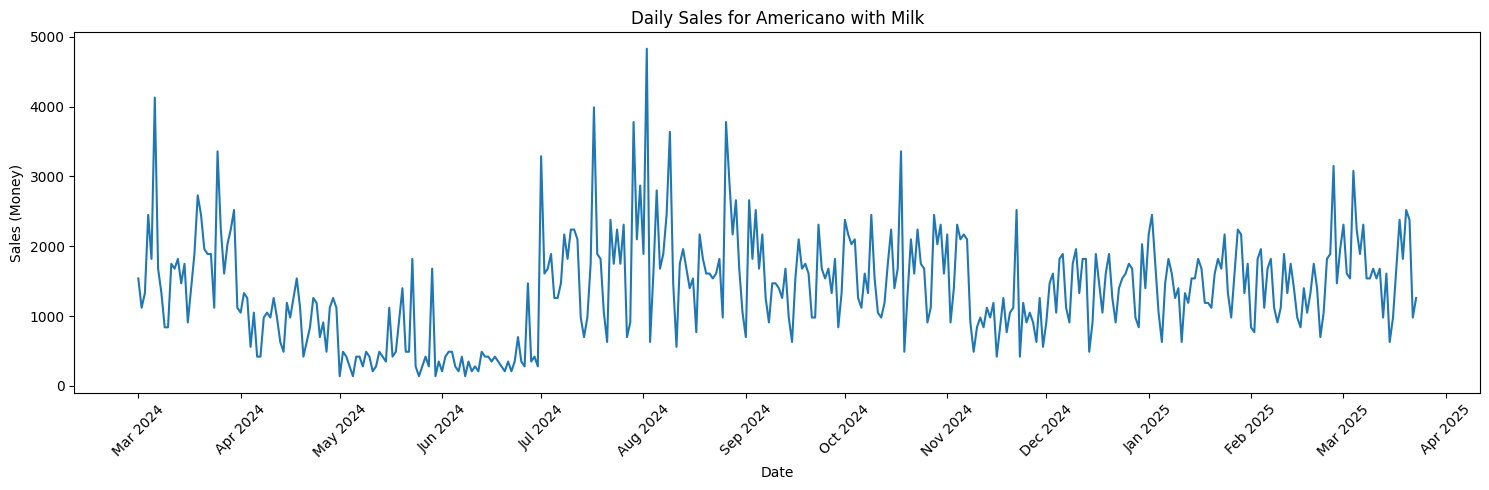

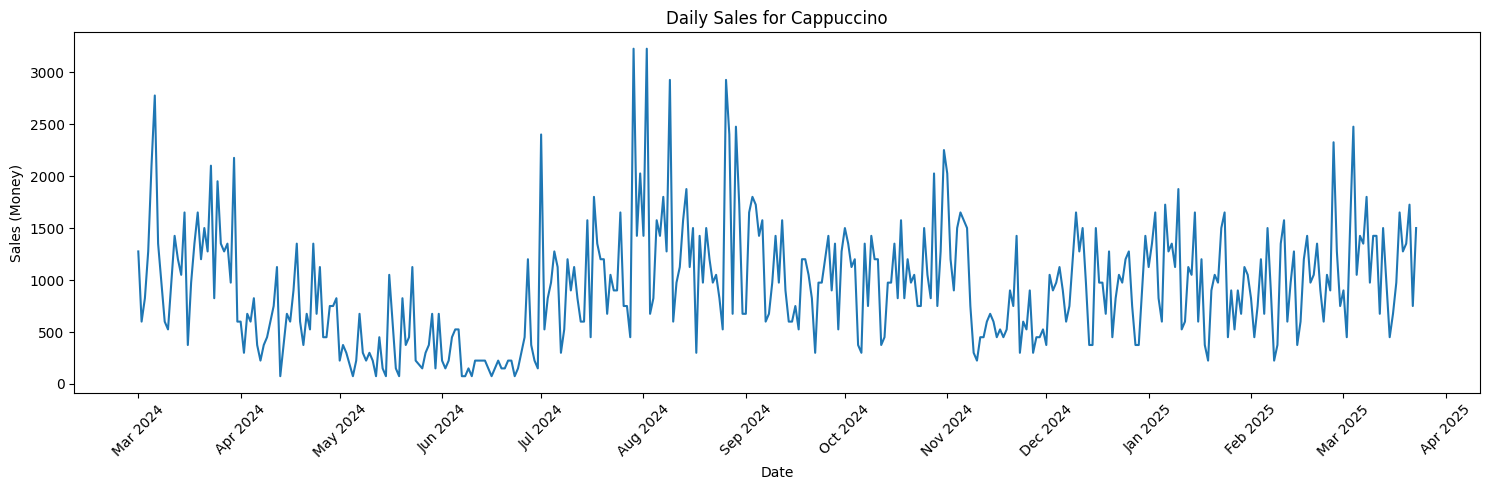

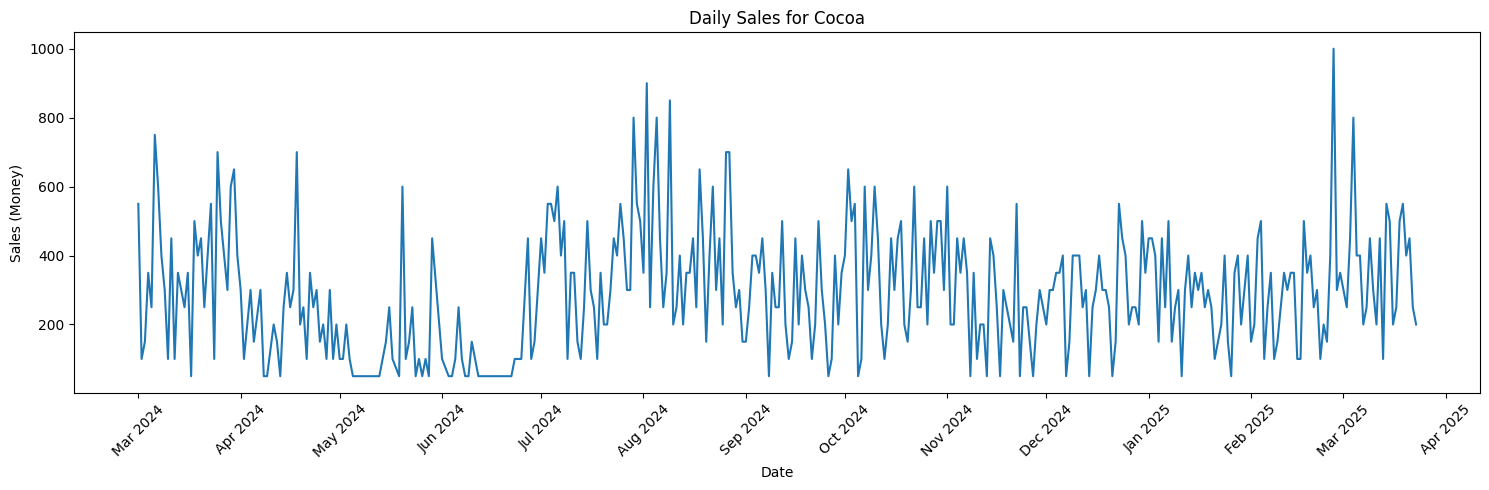

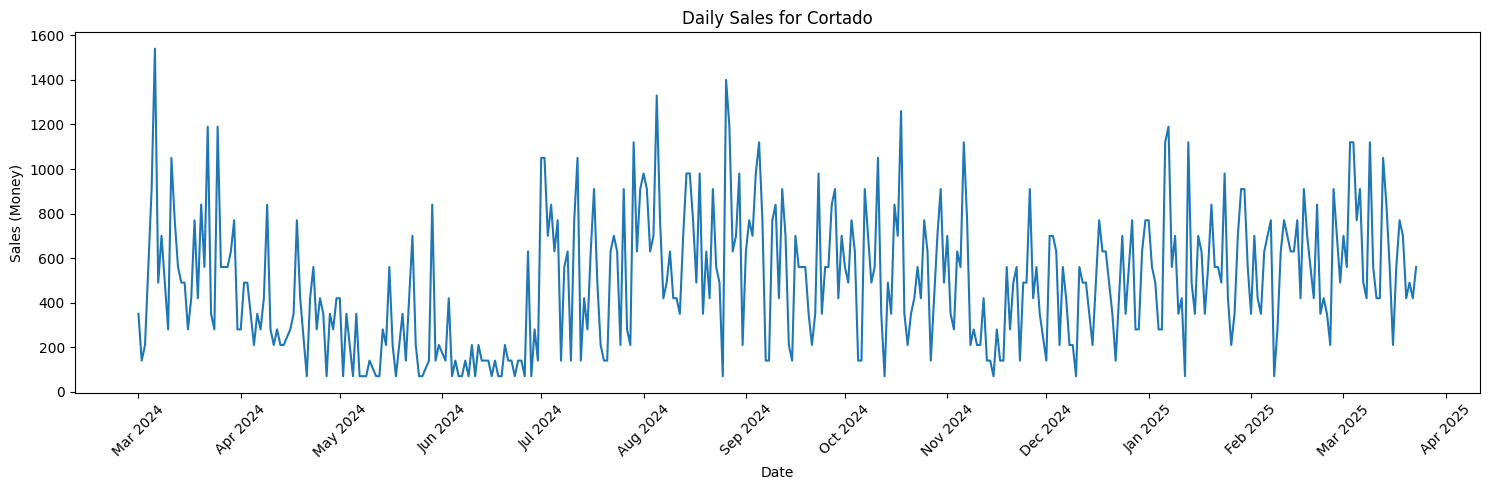

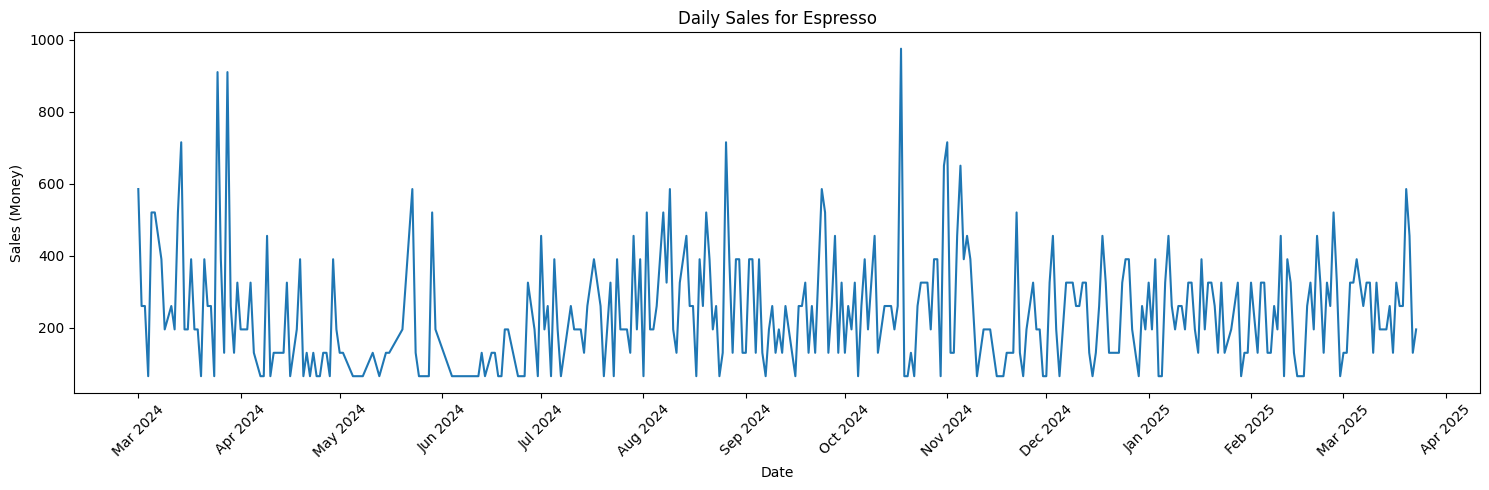

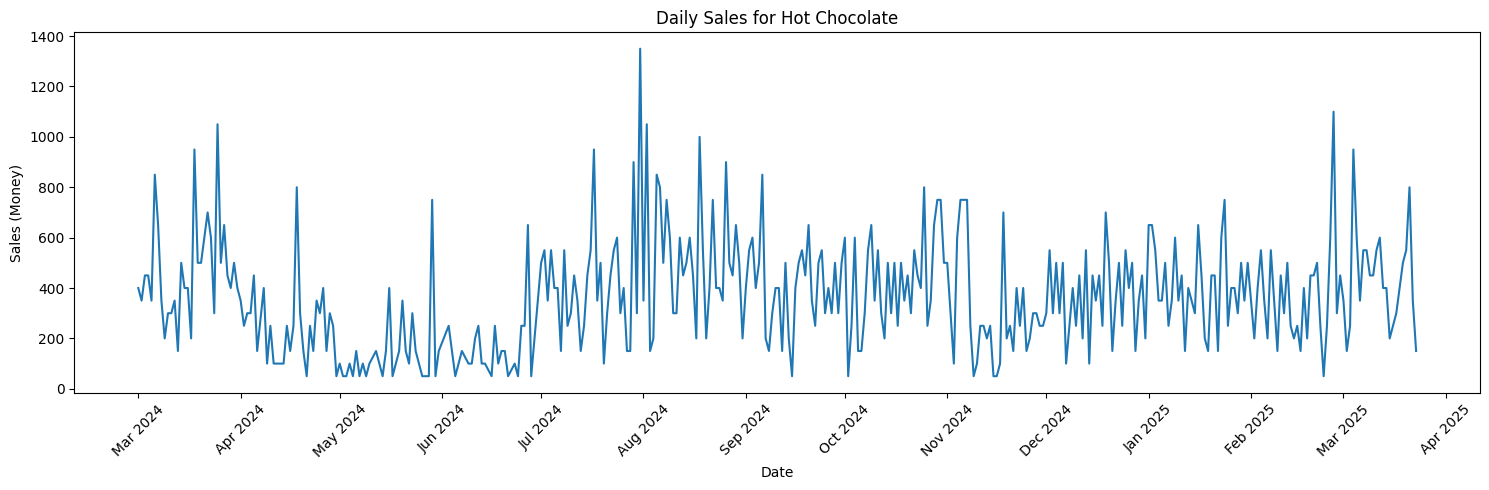

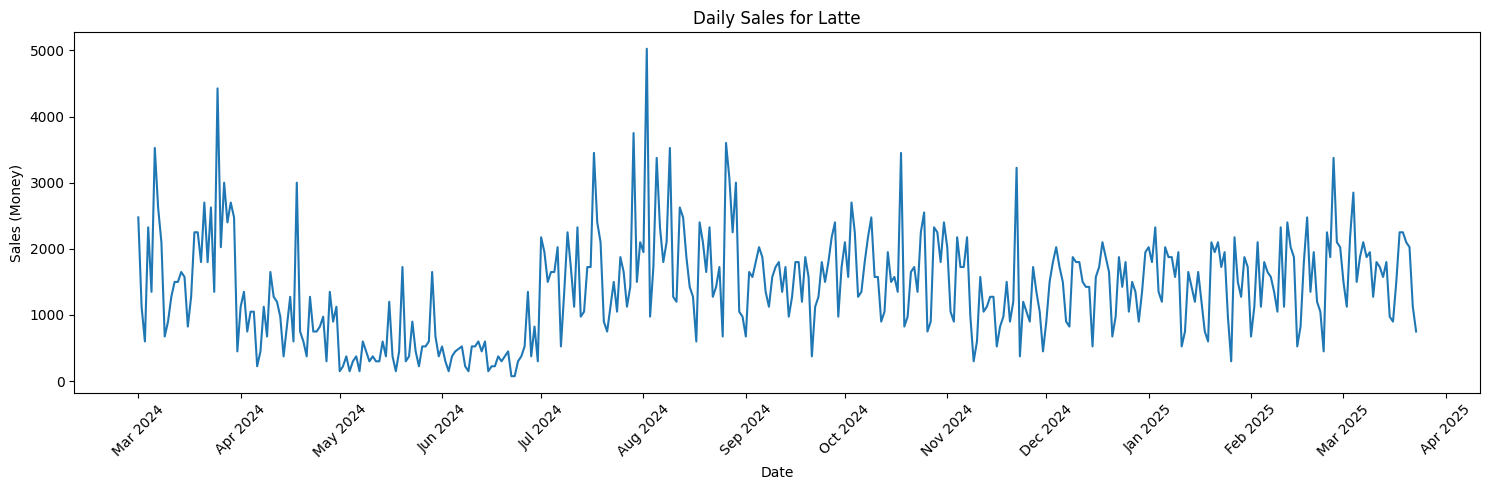

In [9]:
# Plot daily sales for each coffee item
for coffee_name in daily_sales['coffee_name'].unique():
    coffee_sales = daily_sales[daily_sales['coffee_name'] == coffee_name].copy() # Create a copy to avoid SettingWithCopyWarning
    # Ensure date is datetime, convert if needed with the correct format
    if not pd.api.types.is_datetime64_any_dtype(coffee_sales['date']):
         coffee_sales['date'] = pd.to_datetime(coffee_sales['date'], format='%d/%m/%Y', errors='coerce')

    coffee_sales.dropna(subset=['date'], inplace=True) # Remove rows with invalid dates

    # Filter data by date range
    # Update start and end dates if needed based on the correct format
    start_date = '2024-03-01' # Assuming the user wants to start from March 1, 2024
    end_date = '2025-03-23'
    coffee_sales = coffee_sales[(coffee_sales['date'] >= start_date) & (coffee_sales['date'] <= end_date)]

    coffee_sales.set_index('date', inplace=True) # Set date as index for easier plotting


    plt.figure(figsize=(15, 5))
    plt.plot(coffee_sales.index, coffee_sales['money'])
    plt.title(f'Daily Sales for {coffee_name}')
    plt.xlabel('Date')
    plt.ylabel('Sales (Money)')

    # Format x-axis to show month and year
    plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())


    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [10]:
def create_sales_features(df):
    # Ensure date is datetime and set as index
    # Check if date is already datetime, if not convert with the correct format
    if not pd.api.types.is_datetime64_any_dtype(df['date']):
        df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')

    df.set_index('date', inplace=True)

    # Create features from date
    df['dayofweek'] = df.index.dayofweek # 0 = Monday, 6 = Sunday
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['dayofyear'] = df.index.dayofyear
    df['year'] = df.index.year # Add year feature

    # Sort by date before creating lag features
    df.sort_index(inplace=True)

    # Create Lag Features (previous sales)
    # We'll use data from 7 days and 14 days ago to help predict
    df['lag_7'] = df['total_sales'].shift(7)
    df['lag_14'] = df['total_sales'].shift(14)

    # Create Rolling Mean
    df['rolling_mean_7'] = df['total_sales'].shift(1).rolling(window=7).mean()

    # Reset index to make date a column again
    df.reset_index(inplace=True)

    return df


daily_total_sales_features = create_sales_features(daily_total_sales.copy())


# Drop rows with NaN values created by lag features
daily_total_sales_features.dropna(inplace=True)

display(daily_total_sales_features.head())

,date,total_sales,dayofweek,quarter,month,dayofyear,year,lag_7,lag_14,rolling_mean_7
14,2023-03-15,7200,2,1,3,74,2023,7290.0,8645.0,6460.000000
15,2023-03-16,7315,3,1,3,75,2023,7140.0,8560.0,6447.142857
16,2023-03-17,7510,4,1,3,76,2023,7120.0,8690.0,6472.142857
17,2023-03-18,5250,5,1,3,77,2023,5735.0,4365.0,6527.857143
18,2023-03-19,4765,6,1,3,78,2023,3635.0,4565.0,6458.571429


In [11]:
# Convert 'date' column to datetime objects
# Ensure 'date' is a column first if it was set as index
if df.index.name == 'date':
    df.reset_index(inplace=True)

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')

# Display the data types to confirm the conversion
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68359 entries, 0 to 68358
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         68359 non-null  datetime64[ns]
 1   time         68359 non-null  object        
 2   cash_type    68359 non-null  object        
 3   coffee_name  68359 non-null  object        
 4   money        68359 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 2.6+ MB


None

In [12]:
FEATURES = ['dayofweek', 'quarter', 'month', 'dayofyear', 'lag_7', 'lag_14', 'rolling_mean_7']
TARGET = 'total_sales'

In [13]:
X = daily_total_sales_features[FEATURES]
y = daily_total_sales_features[TARGET]

In [14]:
# Determine the split date
split_date = '2025-03-01'

# Ensure the 'date' column is in datetime format for comparison
daily_total_sales_features['date'] = pd.to_datetime(daily_total_sales_features['date'])

# Split data into training and testing sets based on date
train_data = daily_total_sales_features[daily_total_sales_features['date'] < split_date]
test_data = daily_total_sales_features[daily_total_sales_features['date'] >= split_date]

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_test = test_data[FEATURES]
y_test = test_data[TARGET]


print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (717, 7)
Shape of y_train: (717,)
Shape of X_test: (61, 7)
Shape of y_test: (61,)


In [15]:
# Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [16]:
# XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=100,
                             learning_rate=0.05, # ค่อยๆ เรียนรู้ช้าๆ
                             early_stopping_rounds=10, # ถ้าผลไม่ดีขึ้น 10 รอบให้หยุด
                             random_state=42)

In [17]:
# XGBoost ต้องมี evaluation set เพื่อใช้ early stopping
xgb_model.fit(X_train, y_train,
              eval_set=[(X_test, y_test)],
              verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=10,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [18]:
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

In [19]:
rf_mae = mean_absolute_error(y_test, rf_pred)
xgb_mae = mean_absolute_error(y_test, xgb_pred)

In [20]:
print(f"\nความคลาดเคลื่อนเฉลี่ยของ Random Forest: {rf_mae:.2f} จากทั้งหมด {len(y_test)} จุดข้อมูล")
print(f"ความคลาดเคลื่อนเฉลี่ยของ XGBoost: {xgb_mae:.2f} จากทั้งหมด {len(y_test)} จุดข้อมูล")
print(f"ยอดขายรวมใน Test Set: {y_test.sum():.2f} บาท")


ความคลาดเคลื่อนเฉลี่ยของ Random Forest: 1128.13 จากทั้งหมด 61 จุดข้อมูล
ความคลาดเคลื่อนเฉลี่ยของ XGBoost: 1035.21 จากทั้งหมด 61 จุดข้อมูล
ยอดขายรวมใน Test Set: 366330.00 บาท


In [21]:
results = pd.DataFrame({
    'Actual': y_test,
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred
})

# Set the index of the results DataFrame to the dates from the test set
results.index = test_data['date']

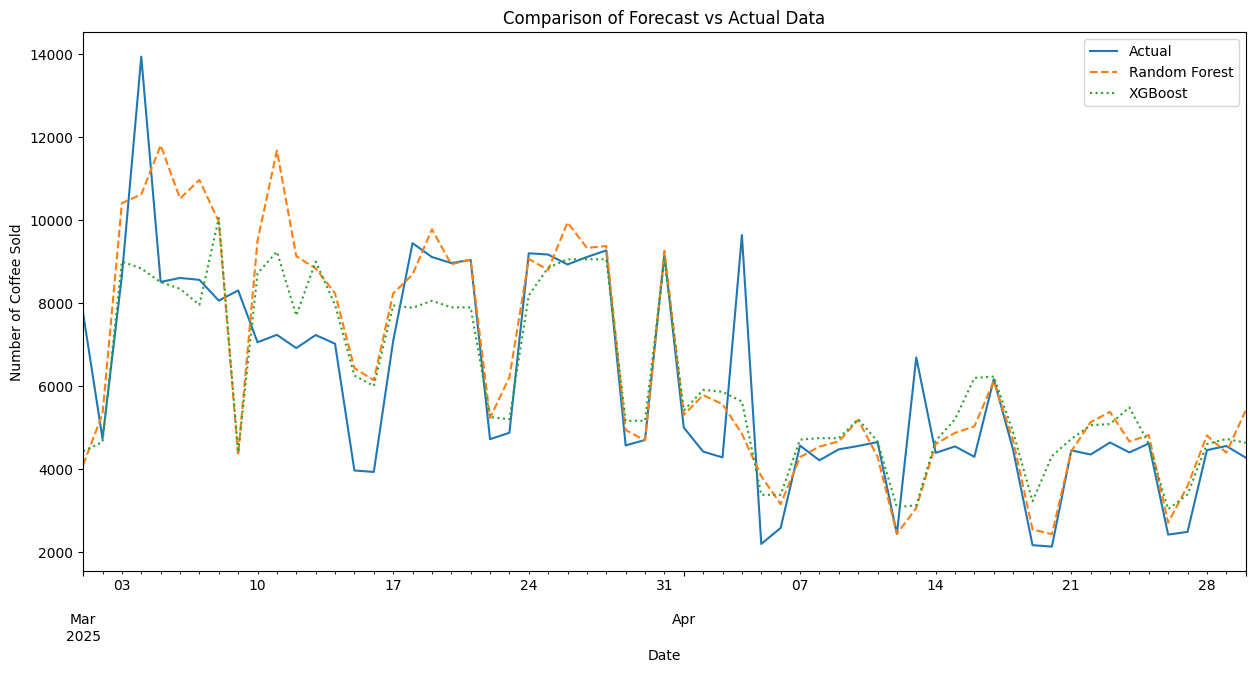

In [22]:
results.plot(figsize=(15, 7), style=['-', '--', ':'],
             title='Comparison of Forecast vs Actual Data')
plt.ylabel('Number of Coffee Sold')
plt.xlabel('Date')
plt.legend()
plt.show()

In [23]:
def plot_feature_importance(model, features, model_name):
    # สร้าง DataFrame ของ feature importance
    fi = pd.DataFrame(data=model.feature_importances_,
                      index=features,
                      columns=['importance'])
    fi_sorted = fi.sort_values('importance', ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=fi_sorted.index, y=fi_sorted['importance'])
    plt.title(f'Feature Importance of the {model_name} Model') # Changed title to English
    plt.xticks(rotation=45)
    plt.xlabel('Features') # Added x-axis label
    plt.show()

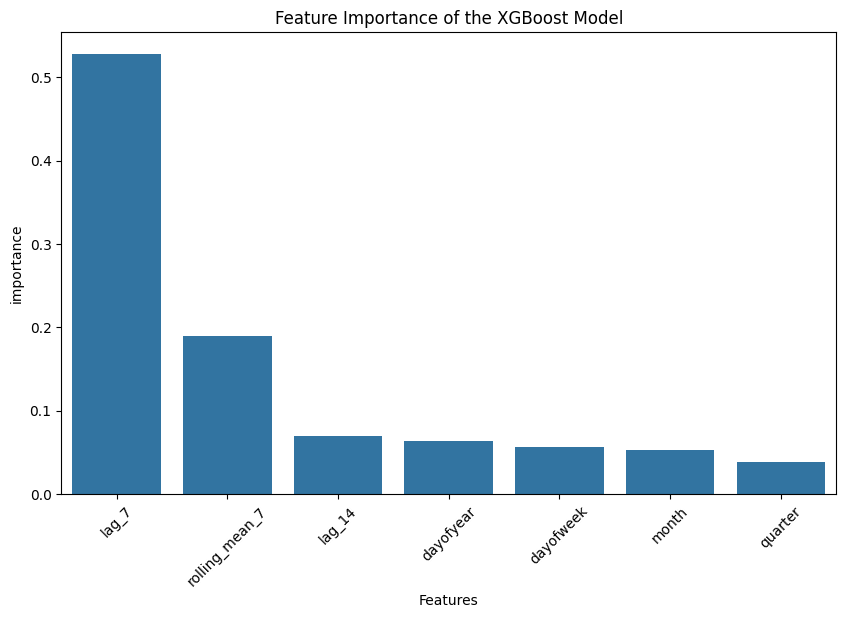

In [24]:
plot_feature_importance(xgb_model, FEATURES, 'XGBoost')

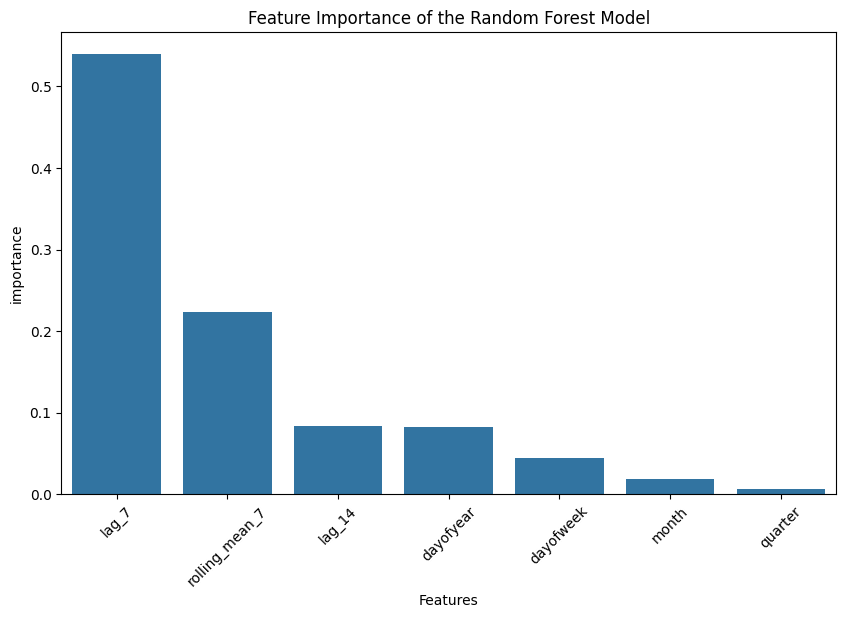

In [25]:
plot_feature_importance(rf_model, FEATURES, 'Random Forest')

In [26]:
#ใช้  prophet

In [27]:
!pip install prophet

In [28]:
from prophet import Prophet

In [29]:
# Prepare data for Prophet: requires 'ds' (datetime) and 'y' (target) columns
# Use the already split train_data and test_data DataFrames

# Add print statements to check columns
print("Columns in train_data:", train_data.columns)
print("Columns in test_data:", test_data.columns)

Columns in train_data: Index(['date', 'total_sales', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'lag_7', 'lag_14', 'rolling_mean_7'],
      dtype='object')
Columns in test_data: Index(['date', 'total_sales', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'lag_7', 'lag_14', 'rolling_mean_7'],
      dtype='object')


In [30]:
prophet_train = train_data[['date', 'total_sales']].rename(columns={'date': 'ds', 'total_sales': 'y'})
prophet_test = test_data[['date', 'total_sales']].rename(columns={'date': 'ds', 'total_sales': 'y'})

# Prophet requires a continuous time series without missing dates.
# It's generally recommended to ensure the data has a daily frequency and fill missing dates if necessary.
# For simplicity now, we'll use the data as is, but note this for potential issues.
# If there are missing dates, Prophet can handle them to some extent but performance might be affected.

In [31]:
# Initialize and fit the Prophet model
model = Prophet(weekly_seasonality=True,yearly_seasonality=True)
model.fit(prophet_train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmp1_lualz1/og_dv0ss.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp1_lualz1/9ecqjmk5.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=29048', 'data', 'file=/tmp/tmp1_lualz1/og_dv0ss.json', 'init=/tmp/tmp1_lualz1/9ecqjmk5.json', 'output', 'file=/tmp/tmp1_lualz1/prophet_modelxznquv1_/prophet_model-20250921151443.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
15:14:43 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
15:14:43 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


In [32]:
# Display the index (dates) of the RF/XGBoost test set
display(y_test.index)

Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744,
       745, 746, 747, 748, 749, 750, 751, 752, 753, 754, 755, 756, 757, 758,
       759, 760, 761, 762, 763, 764, 765, 766, 767, 768, 769, 770, 771, 772,
       773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786,
       787, 788, 789, 790, 791],
      dtype='int64')

In [33]:
# Create a future dataframe for predictions
# We need to predict for the dates in the test set
future = model.make_future_dataframe(periods=len(prophet_test))

In [34]:
# Make predictions
forecast = model.predict(future)

In [35]:
# Display the forecast
display(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

,ds,yhat,yhat_lower,yhat_upper
0,2023-03-15,9233.730622,6866.604055,11442.231332
1,2023-03-16,9251.532056,6910.363801,11756.454858
2,2023-03-17,8906.581304,6604.243111,11494.976584
3,2023-03-18,5968.444038,3800.818739,8347.678381
4,2023-03-19,6036.730926,3665.294540,8385.286667


In [36]:
# Evaluate the Prophet model
# Merge actual values with forecast
prophet_results = forecast.set_index('ds')[['yhat']].join(prophet_test.set_index('ds')[['y']])
prophet_results.dropna(inplace=True) # Drop rows where there are no actual values (if future was longer than test)

In [37]:
# Calculate MAE
prophet_mae = mean_absolute_error(prophet_results['y'], prophet_results['yhat'])

print(f"ความคลาดเคลื่อนเฉลี่ยของ Prophet: {prophet_mae:.2f} จากทั้งหมด {len(prophet_results)} จุดข้อมูล")
print(f"ยอดขายรวมใน Test Set (สำหรับ Prophet): {prophet_results['y'].sum():.2f} บาท")

ความคลาดเคลื่อนเฉลี่ยของ Prophet: 1180.71 จากทั้งหมด 61 จุดข้อมูล
ยอดขายรวมใน Test Set (สำหรับ Prophet): 366330.00 บาท


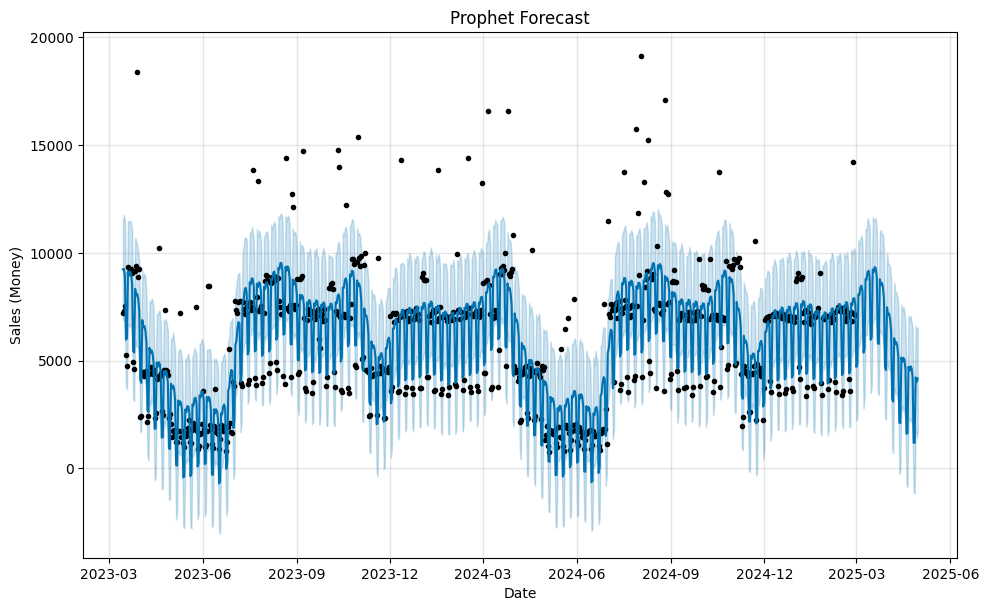

In [38]:
# Plot the forecast
fig1 = model.plot(forecast)
plt.title('Prophet Forecast')
plt.xlabel('Date')
plt.ylabel('Sales (Money)')
plt.show()

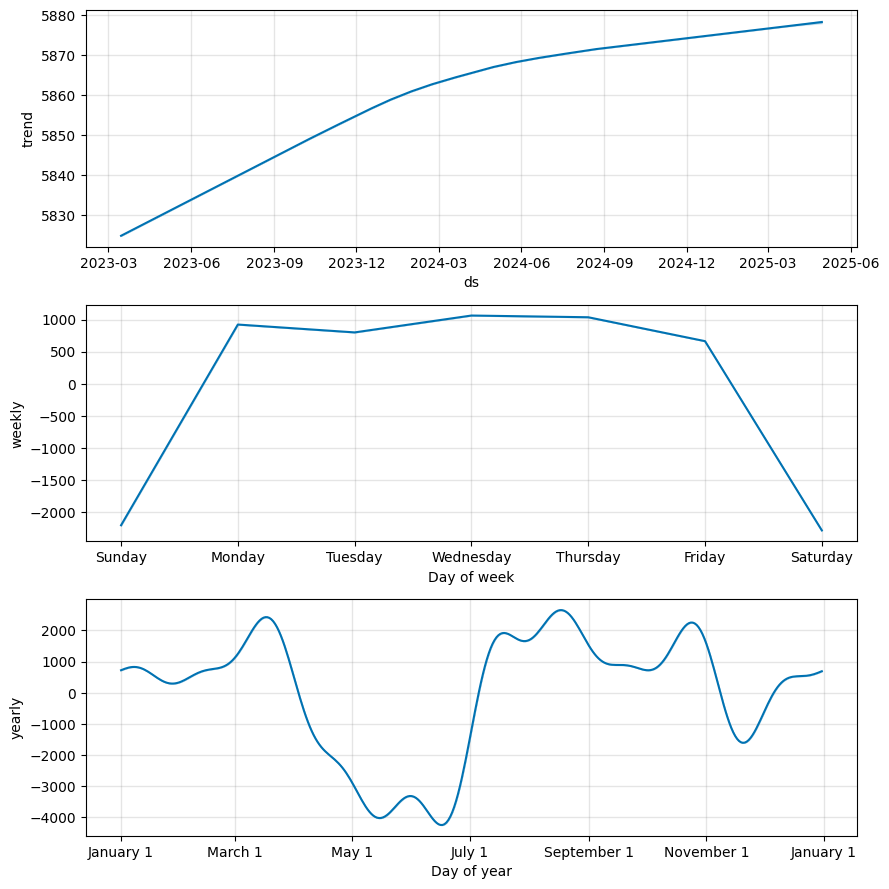

In [39]:
# Plot the components of the forecast
fig2 = model.plot_components(forecast)
plt.show()

In [40]:
pip install git+https://github.com/amazon-science/chronos-forecasting.git

  Cloning https://github.com/amazon-science/chronos-forecasting.git to /tmp/pip-req-build-kh067r1a
  Running command git clone --filter=blob:none --quiet https://github.com/amazon-science/chronos-forecasting.git /tmp/pip-req-build-kh067r1a
  Resolved https://github.com/amazon-science/chronos-forecasting.git to commit fcd09fe8b6bf57643bde7847bf42a6719b7ee205
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for chronos-forecasting: filename=chronos_forecasting-1.5.3-py3-none-any.whl size=29457 sha256=1ed17963a7cb042bbb2bbd927e0f5c26133b09dc77300086832dedd8cf911cd2
  Stored in directory: /tmp/pip-ephem-wheel-cache-pumov5dt/wheels/b9/a6/b5/75fca7306751a3bc92a63680f861f44a42a8776f6423cf0188
Successfully built chronos-forecasting


In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from chronos import ChronosPipeline

In [42]:
pipeline = ChronosPipeline.from_pretrained(
  "amazon/chronos-t5-small",
  device_map="cuda",
  dtype=torch.bfloat16,
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/185M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

In [ ]:
# Prepare the data for Chronos
# Chronos expects a torch tensor as input. We'll use the 'total_sales' column
# Filter data before the split date
split_date = pd.to_datetime('2025-03-01')
historical_sales_before_split = daily_total_sales[daily_total_sales['date'] < split_date].copy()


# Convert the 'total_sales' column from the filtered data to a torch tensor
context = torch.tensor(historical_sales_before_split['total_sales'].values)

# Define the prediction length (e.g., 60 days for one month forecast)
prediction_length = 60

# Make a forecast using the Chronos pipeline
forecast = pipeline.predict(context, prediction_length)

# The forecast is a distribution. We can get the median prediction.
# The forecast tensor will have shape (num_samples, prediction_length)
# We take the median along the sample dimension (dim=0)
median_prediction = forecast[0].median(dim=0).values

# Display the median prediction
print(f"Chronos Median Forecast for the next {prediction_length} days:")
display(median_prediction)

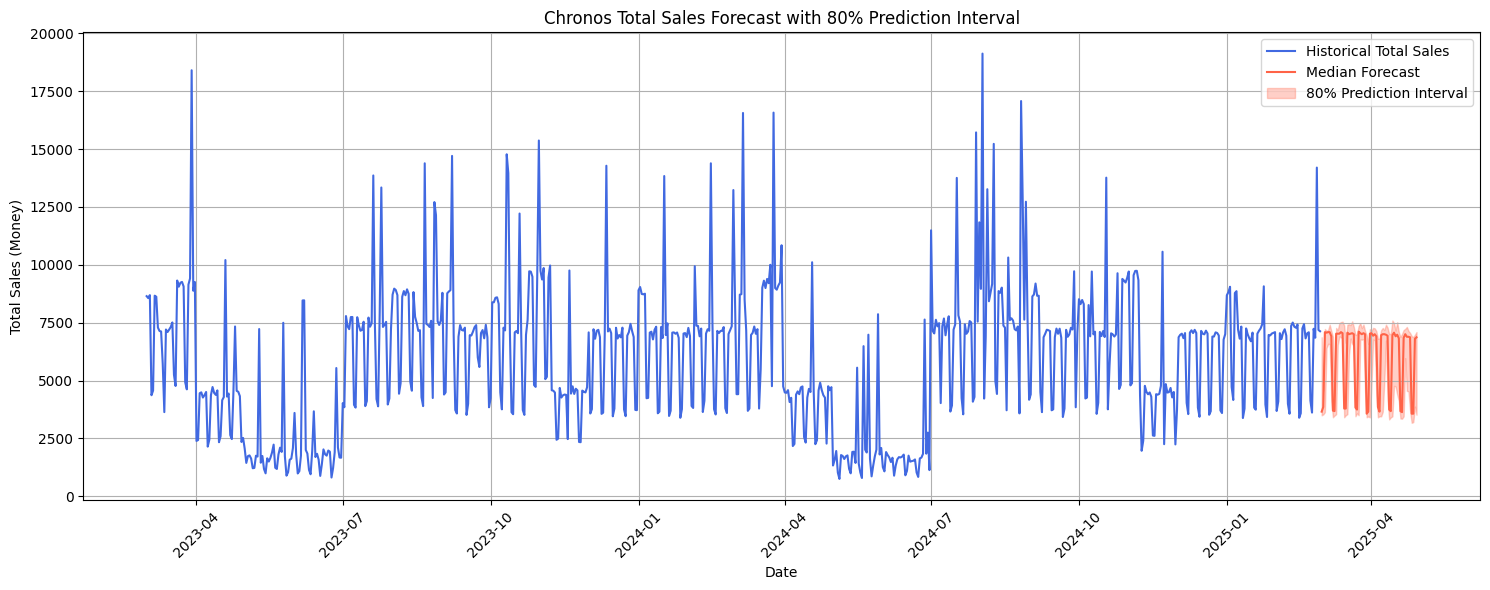

In [44]:
# Visualize the Chronos forecast with prediction interval
plt.figure(figsize=(15, 6))

# Plot historical data (daily_total_sales before split_date)
plt.plot(historical_sales_before_split['date'], historical_sales_before_split['total_sales'], color="royalblue", label="Historical Total Sales")

# Create dates for the forecast period
# The forecast starts immediately after the last date in the historical_sales_before_split
last_date_historical = historical_sales_before_split['date'].iloc[-1]
forecast_dates = pd.date_range(start=last_date_historical + pd.Timedelta(days=1), periods=prediction_length, freq='D')

# Calculate quantiles for the prediction interval
low, median, high = np.quantile(forecast[0].numpy(), [0.1, 0.5, 0.9], axis=0)

# Plot the median forecast
plt.plot(forecast_dates, median, color="tomato", label="Median Forecast")

# Plot the 80% prediction interval
plt.fill_between(forecast_dates, low, high, color="tomato", alpha=0.3, label="80% Prediction Interval")


plt.title('Chronos Total Sales Forecast with 80% Prediction Interval')
plt.xlabel('Date')
plt.ylabel('Total Sales (Money)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
forecast[0][:][0]

tensor([ 4165.4717,  3899.5908,  7311.7324,  4564.2935,  4431.3530,  4741.5479,
         4475.6665,  2304.3037,  2481.5576,  4918.8018,  4741.5479,  9881.9170,
        10059.1709, 10280.7393,  9970.5439,  4741.5479,  9926.2305,  9660.3496,
         9527.4092,  9261.5273,  9261.5273,  4652.9209,  4918.8018, 10059.1709,
         9438.7822,  9305.8408,  9394.4688,  4475.6665,  1905.4819,  2348.6172,
         4874.4883,  4963.1152,  4741.5479,  4741.5479,  4431.3530,  4121.1582,
         4874.4883,  5273.3101,  4918.8018,  5096.0562,  5007.4287,  4963.1152,
         4608.6069,  9704.6631,  9837.6035,  4785.8613,  4785.8613,  4874.4883,
         4874.4883,  4608.6069,  9660.3496,  9704.6631,  9793.2900, 10325.0527,
         4874.4883,  2082.7358,  2259.9900,  2747.4387,  4652.9209,  4564.2935])

In [46]:
median_forecast = np.median(forecast[0], axis=0)

print("ค่ามัธยฐานของผลการพยากรณ์ 12 เดือนข้างหน้า")
print(median_forecast)

ค่ามัธยฐานของผลการพยากรณ์ 12 เดือนข้างหน้า
[3655.8662 3855.2769 7090.164  7068.0073 7090.164  7090.164  6912.91
 3700.1797 3678.023  7023.694  7023.694  7023.694  7090.164  7045.8506
 3788.8066 3788.8066 7068.0073 7001.537  7023.694  7045.8506 7001.537
 3833.12   3744.4932 7112.3213 7045.8506 7001.537  7045.8506 7001.537
 3567.2393 3655.8662 7023.694  7045.8506 6935.067  7001.537  6912.91
 3855.277  3655.8662 6957.2236 7001.537  7001.537  6979.3804 6935.067
 3744.4932 3678.023  6957.2236 7068.0073 6912.91   6979.3804 6824.283
 3678.023  3633.7095 6846.44   7001.537  6890.7534 6890.7534 6868.5967
 3567.2393 3567.2393 6802.1265 6868.5967]


### **Predic จำนวนแก้วที่ขายได้ในแต่ละวัน 60 วัน ( 2 เดือน ) แยกแต่ละเมนูขายได้กี่แก้ว**

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

# สรุปยอดขายต่อวันต่อเมนู
sales_by_product = df.groupby(["date", "coffee_name"]).size().reset_index(name="cups")
print(sales_by_product.head())


Saving cafethai_prices.csv to cafethai_prices (9).csv
        date          coffee_name  cups
0 2023-03-01            Americano    19
1 2023-03-01  Americano with Milk    27
2 2023-03-01           Cappuccino    24
3 2023-03-01                Cocoa     7
4 2023-03-01              Cortado    14


Americano: ค่าเฉลี่ยต่อวัน = 13.70 แก้ว,
 คาดว่า 60 วัน ≈ 822 แก้ว


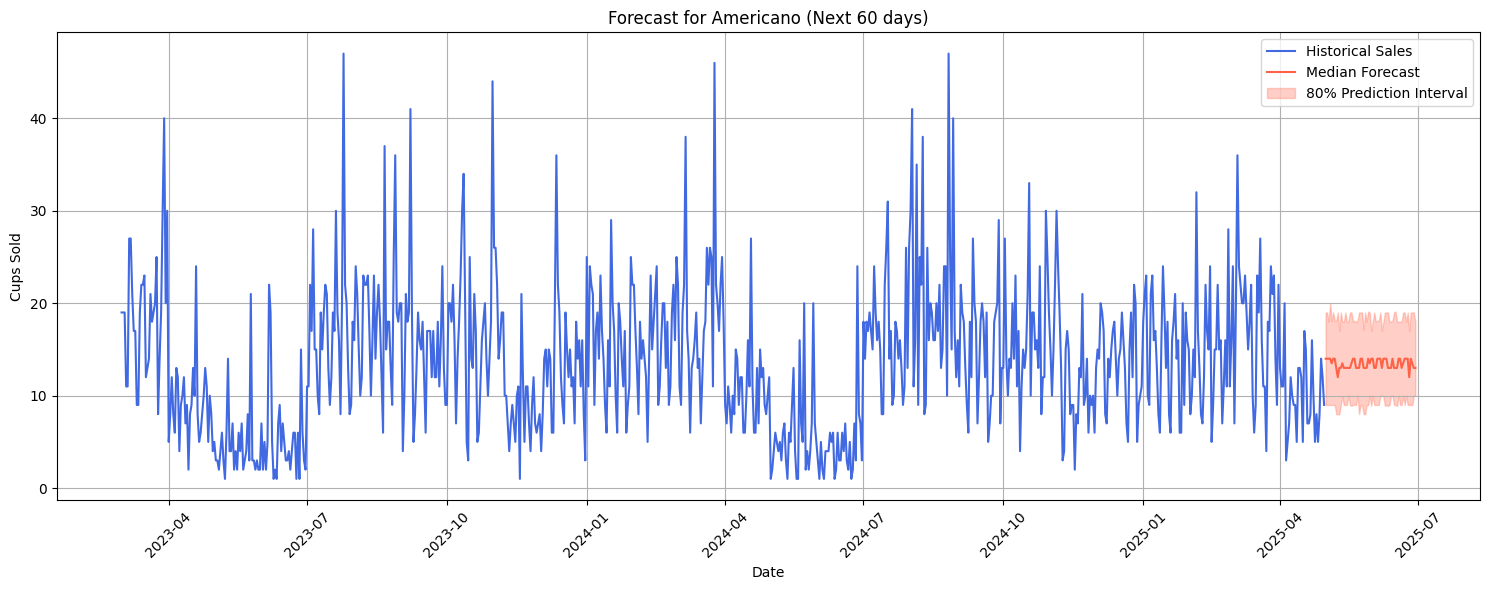

Americano with Milk: ค่าเฉลี่ยต่อวัน = 19.16 แก้ว,
 คาดว่า 60 วัน ≈ 1149 แก้ว


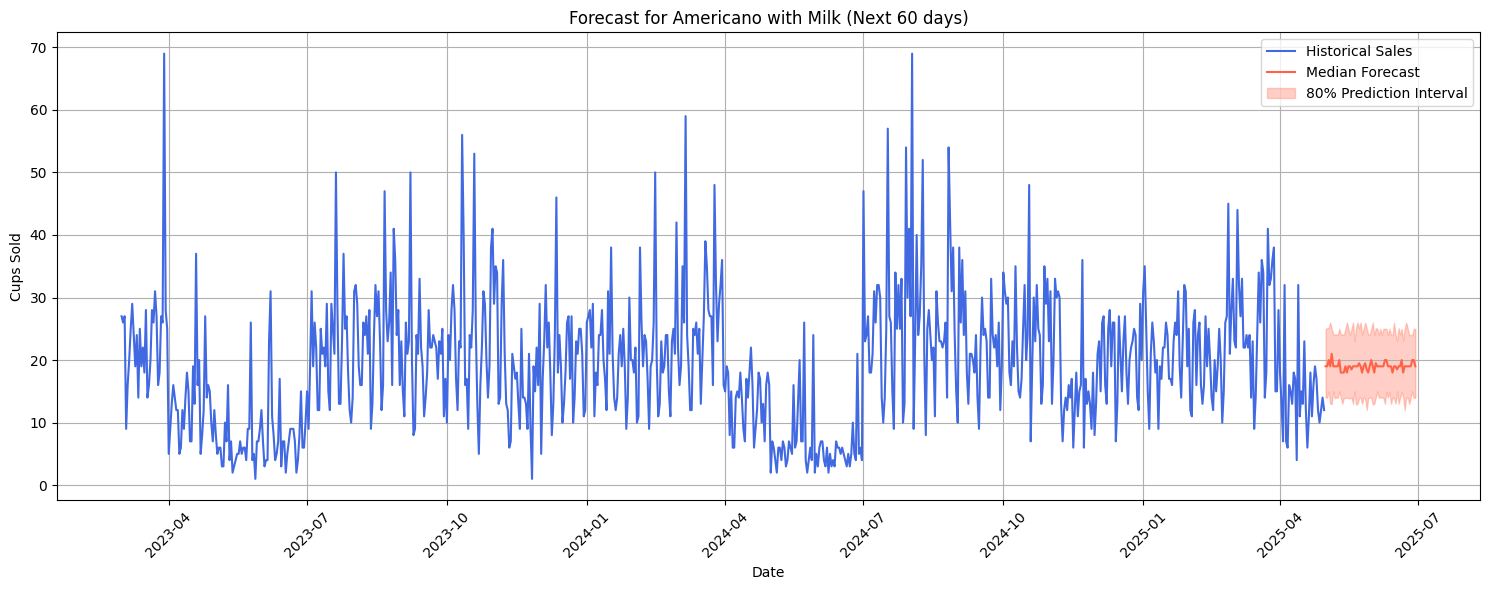

Cappuccino: ค่าเฉลี่ยต่อวัน = 12.38 แก้ว,
 คาดว่า 60 วัน ≈ 743 แก้ว


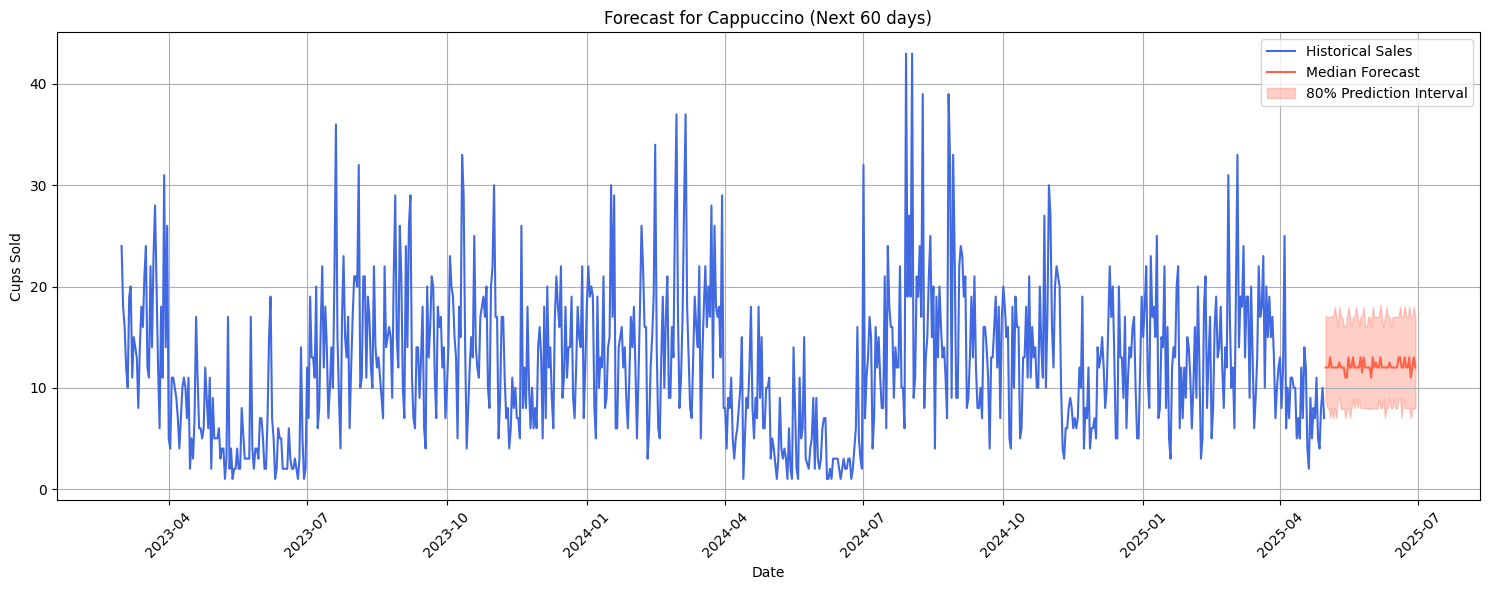

Cocoa: ค่าเฉลี่ยต่อวัน = 5.85 แก้ว,
 คาดว่า 60 วัน ≈ 351 แก้ว


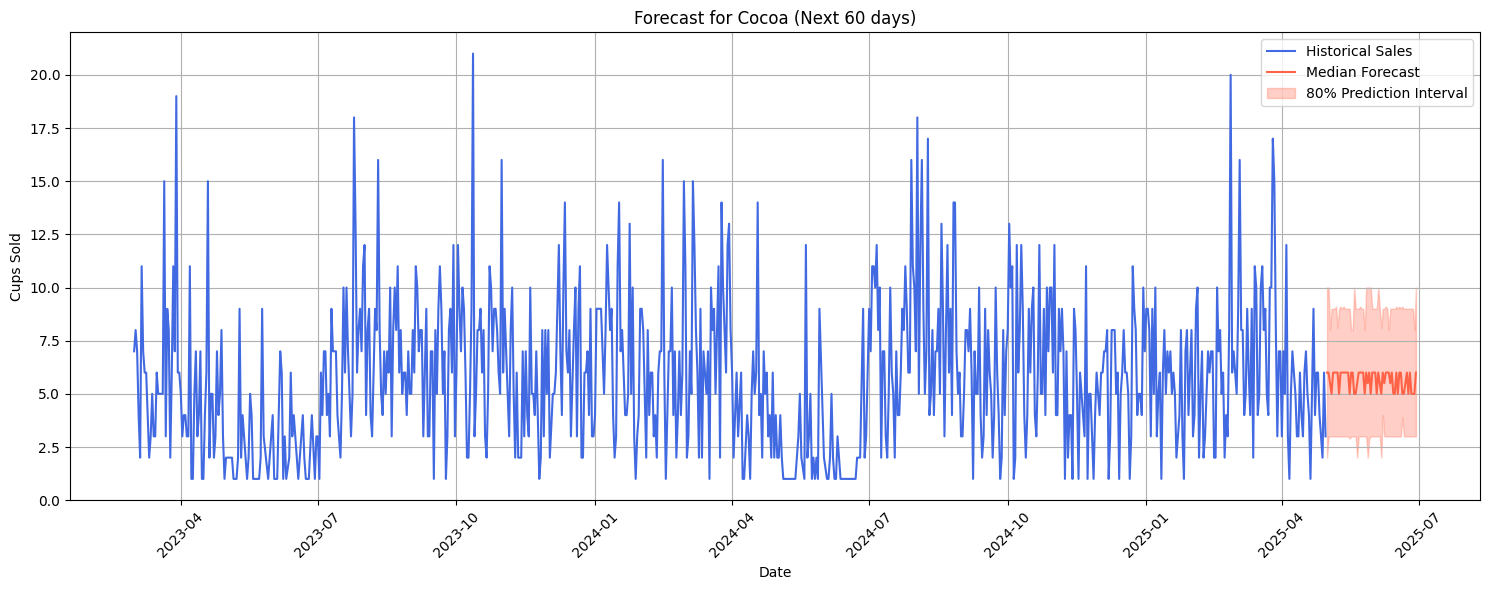

Cortado: ค่าเฉลี่ยต่อวัน = 7.02 แก้ว,
 คาดว่า 60 วัน ≈ 421 แก้ว


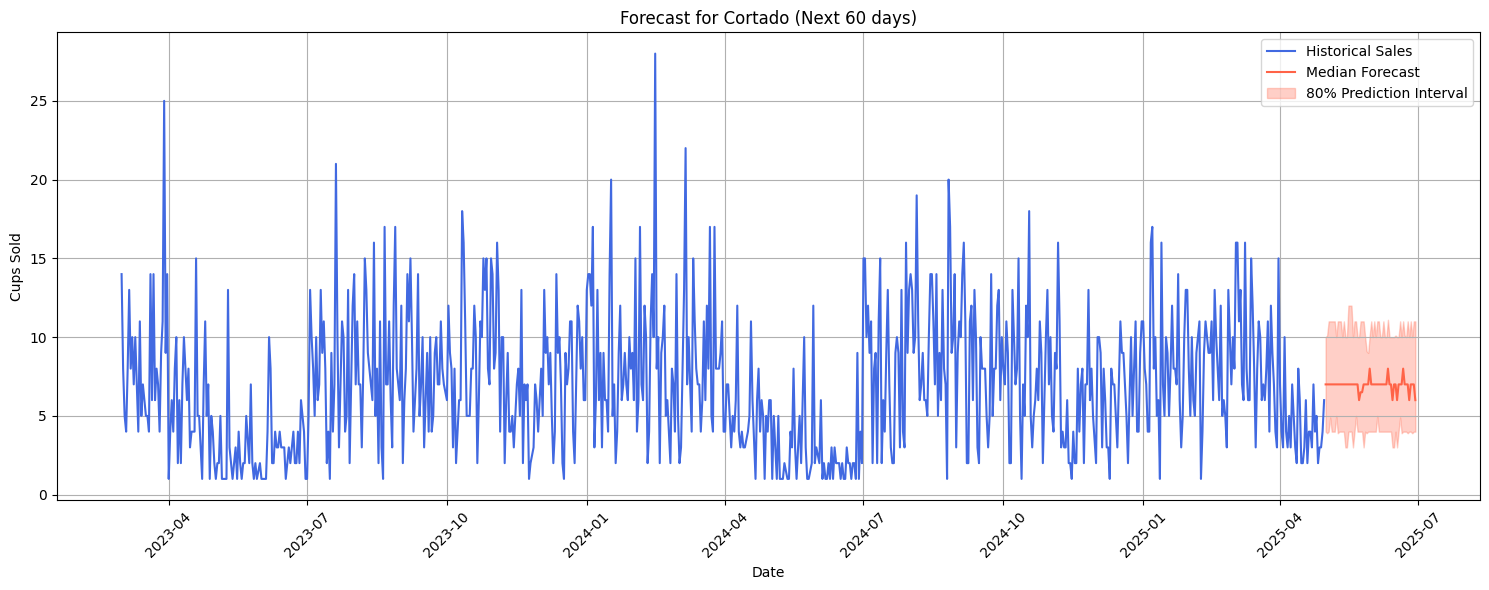

Espresso: ค่าเฉลี่ยต่อวัน = 3.70 แก้ว,
 คาดว่า 60 วัน ≈ 222 แก้ว


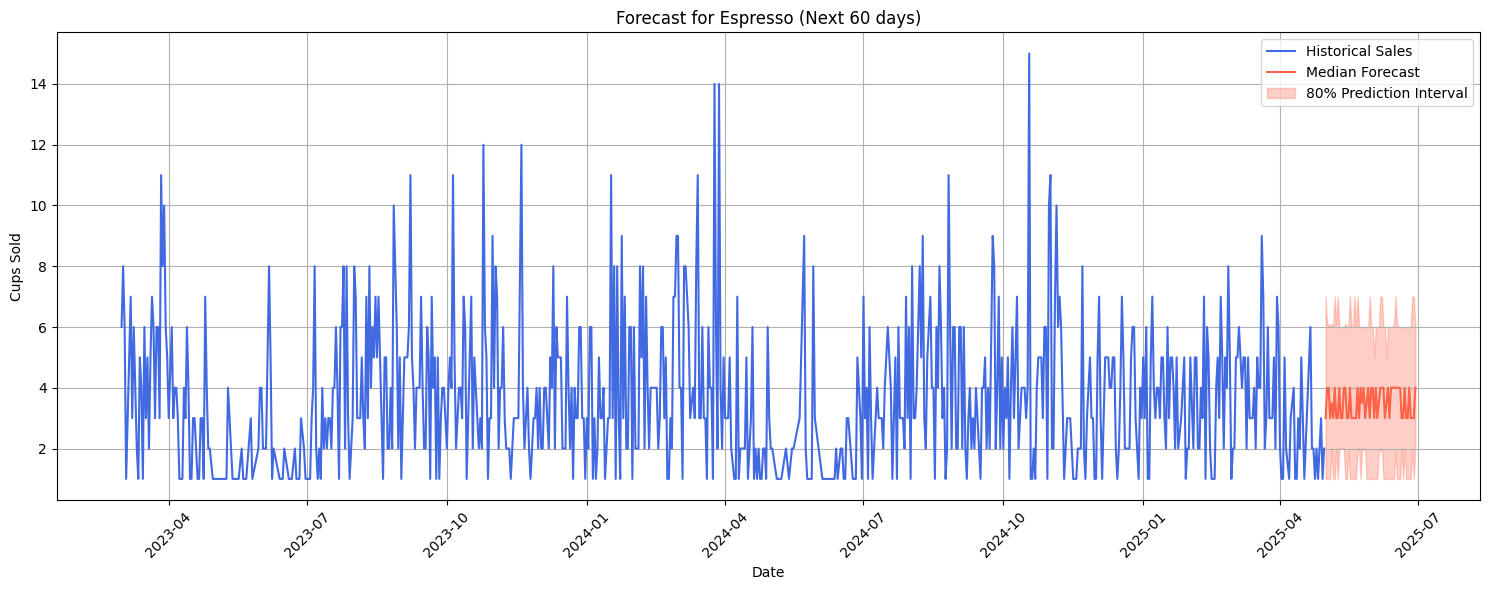

Hot Chocolate: ค่าเฉลี่ยต่อวัน = 6.98 แก้ว,
 คาดว่า 60 วัน ≈ 419 แก้ว


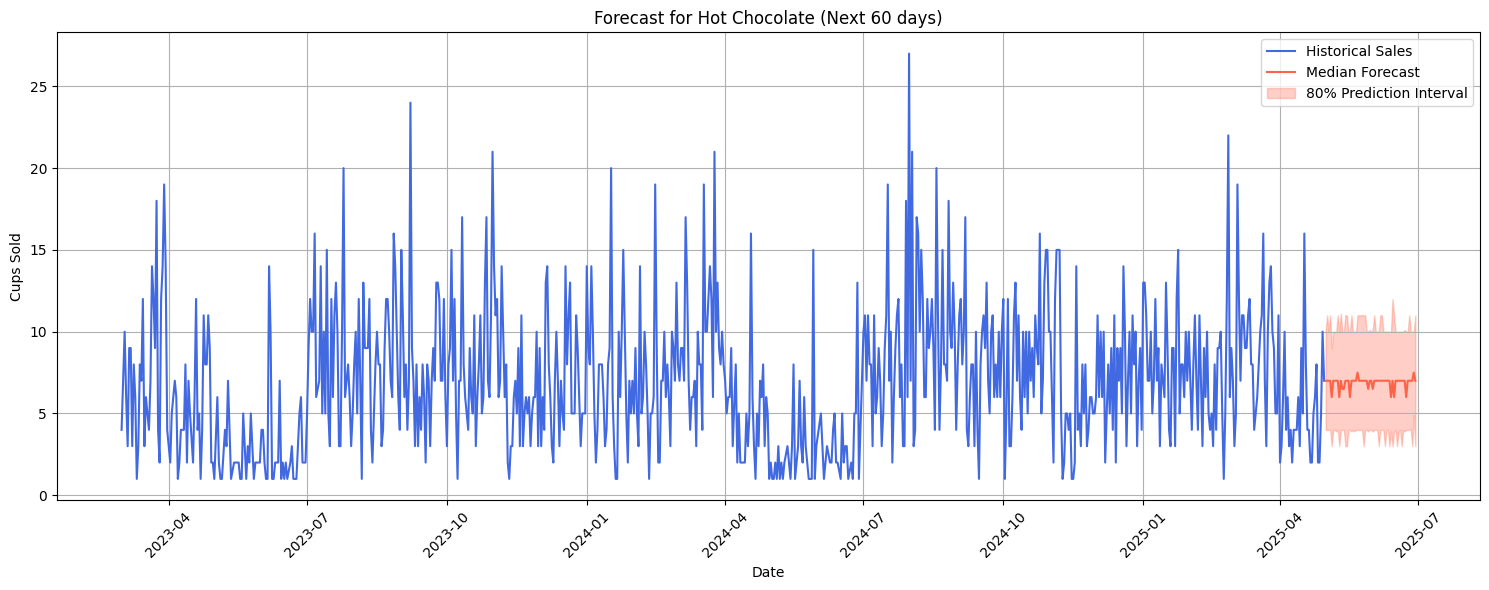

Latte: ค่าเฉลี่ยต่อวัน = 18.70 แก้ว,
 คาดว่า 60 วัน ≈ 1122 แก้ว


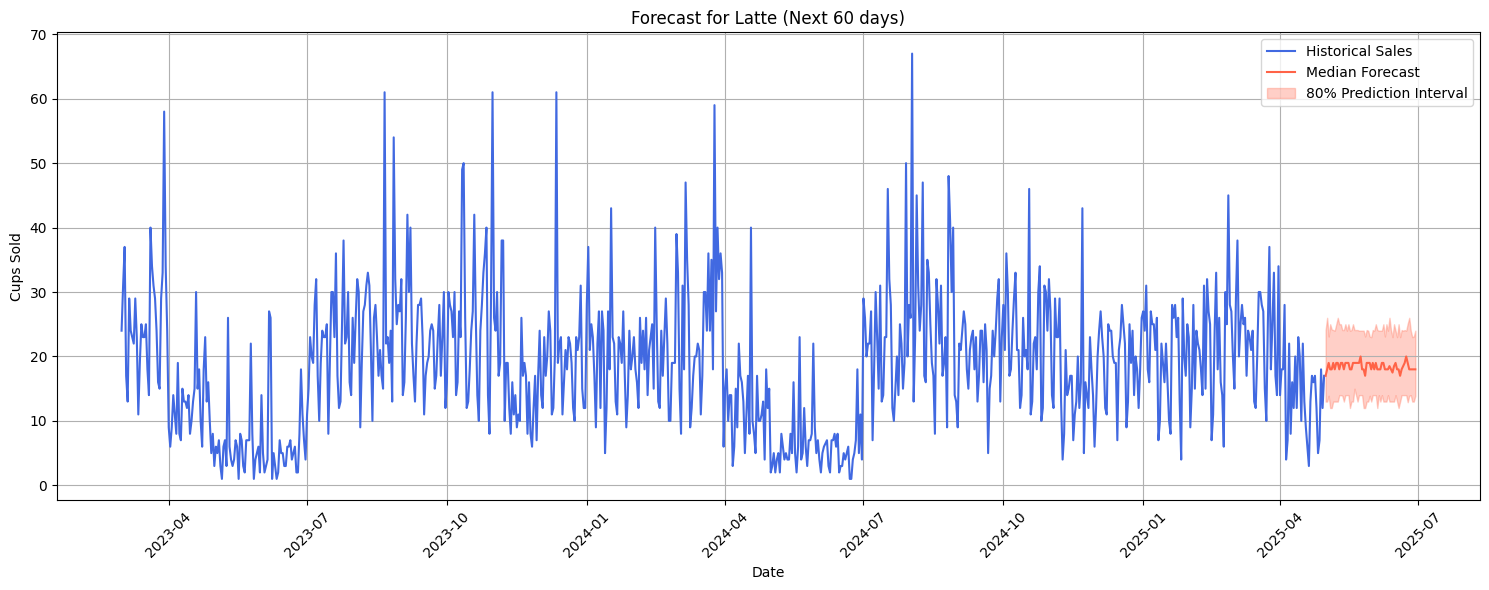


 จำนวนแก้วที่ขายได้ในแต่ละวัน 60 วัน ( 2 เดือน ) แยกแต่ละเมนูขายได้กี่แก้ว = 5249 แก้ว


In [85]:
# ตั้งค่าระยะเวลาที่ต้องการ ( 60 วัน )
prediction_length = 60

forecasts = {}
total_expected_sales = 0

for product in sales_by_product["coffee_name"].unique():
    product_data = sales_by_product[sales_by_product["coffee_name"] == product].copy()
    product_data = product_data.sort_values("date")

    # ค่าเฉลี่ยต่อวัน
    avg_daily_sales = product_data["cups"].mean()
    print(f"{product}: ค่าเฉลี่ยต่อวัน = {avg_daily_sales:.2f} แก้ว,")


    # คาดการณ์ยอดขายรวม 60 วัน
    expected_2months_sales = avg_daily_sales * prediction_length
    total_expected_sales += expected_2months_sales

    print(f" คาดว่า 60 วัน ≈ {expected_2months_sales:.0f} แก้ว")

    # สร้างช่วงวันที่อนาคต
    last_date_historical = product_data["date"].iloc[-1]
    forecast_dates = pd.date_range(start=last_date_historical + pd.Timedelta(days=1),
                                   periods=prediction_length, freq="D")

    # สุ่มการขายด้วย Poisson distribution
    forecast = np.random.poisson(lam=avg_daily_sales, size=(100, prediction_length))

    low, median, high = np.quantile(forecast, [0.1, 0.5, 0.9], axis=0)

    forecasts[product] = {
        "dates": forecast_dates,
        "median": median,
        "low": low,
        "high": high
    }

    #วาดกราฟ
    plt.figure(figsize=(15, 6))
    plt.plot(product_data["date"], product_data["cups"], color="royalblue", label="Historical Sales")
    plt.plot(forecast_dates, median, color="tomato", label="Median Forecast")
    plt.fill_between(forecast_dates, low, high, color="tomato", alpha=0.3, label="80% Prediction Interval")

    plt.title(f"Forecast for {product} (Next {prediction_length} days)")
    plt.xlabel("Date")
    plt.ylabel("Cups Sold")
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

print(f"\n จำนวนแก้วที่ขายได้ในแต่ละวัน 60 วัน ( 2 เดือน ) แยกแต่ละเมนูขายได้กี่แก้ว = {total_expected_sales:.0f} แก้ว")



# **มัธยฐานของจำนวนแก้วในอีก 2 เดือน**

In [86]:
#เมนูทั้งหมด
menu_list = df["coffee_name"].unique()
print("เมนูทั้งหมด:")
for m in menu_list:
    print("เมนู : ", m)

เมนูทั้งหมด:
เมนู :  Latte
เมนู :  Americano with Milk
เมนู :  Cappuccino
เมนู :  Cortado
เมนู :  Americano
เมนู :  Hot Chocolate
เมนู :  Cocoa
เมนู :  Espresso


In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prediction_length = 60  # 2 เดือน
np.random.seed(42)

avg_sales = 7000

กำหนดวันที่เริ่มจากปีล่าสุด

In [89]:
today = pd.Timestamp.today()
start_date = pd.Timestamp(year=today.year, month=1, day=1)
forecast_dates = pd.date_range(start=start_date, periods=prediction_length, freq="D")


จำลองยอดขายต่อวัน (100 รอบ x 60 วัน)

In [90]:
forecast = np.random.poisson(lam=avg_sales, size=(100, prediction_length))

หาค่ามัธยฐานต่อวัน

In [92]:
median_per_day = np.median(forecast, axis=0)

**มัธยฐานแต่ละวัน + กราฟ**

2025-01-01: มัธยฐาน ≈ 7018 แก้ว
2025-01-02: มัธยฐาน ≈ 7002 แก้ว
2025-01-03: มัธยฐาน ≈ 6994 แก้ว
2025-01-04: มัธยฐาน ≈ 7011 แก้ว
2025-01-05: มัธยฐาน ≈ 6982 แก้ว
2025-01-06: มัธยฐาน ≈ 7006 แก้ว
2025-01-07: มัธยฐาน ≈ 6998 แก้ว
2025-01-08: มัธยฐาน ≈ 7020 แก้ว
2025-01-09: มัธยฐาน ≈ 6976 แก้ว
2025-01-10: มัธยฐาน ≈ 7003 แก้ว
2025-01-11: มัธยฐาน ≈ 6986 แก้ว
2025-01-12: มัธยฐาน ≈ 6992 แก้ว
2025-01-13: มัธยฐาน ≈ 7006 แก้ว
2025-01-14: มัธยฐาน ≈ 6992 แก้ว
2025-01-15: มัธยฐาน ≈ 7001 แก้ว
2025-01-16: มัธยฐาน ≈ 6988 แก้ว
2025-01-17: มัธยฐาน ≈ 7009 แก้ว
2025-01-18: มัธยฐาน ≈ 6998 แก้ว
2025-01-19: มัธยฐาน ≈ 6984 แก้ว
2025-01-20: มัธยฐาน ≈ 7003 แก้ว
2025-01-21: มัธยฐาน ≈ 7002 แก้ว
2025-01-22: มัธยฐาน ≈ 7012 แก้ว
2025-01-23: มัธยฐาน ≈ 7000 แก้ว
2025-01-24: มัธยฐาน ≈ 6999 แก้ว
2025-01-25: มัธยฐาน ≈ 6984 แก้ว
2025-01-26: มัธยฐาน ≈ 6995 แก้ว
2025-01-27: มัธยฐาน ≈ 6996 แก้ว
2025-01-28: มัธยฐาน ≈ 7016 แก้ว
2025-01-29: มัธยฐาน ≈ 6996 แก้ว
2025-01-30: มัธยฐาน ≈ 6990 แก้ว
2025-01-31: มัธยฐาน ≈ 7007 แก้ว
2025-02-

/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3633 (\N{THAI CHARACTER MAI HAN-AKAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3608 (\N{THAI CHARACTER THO THONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2661645750.py:13: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
 

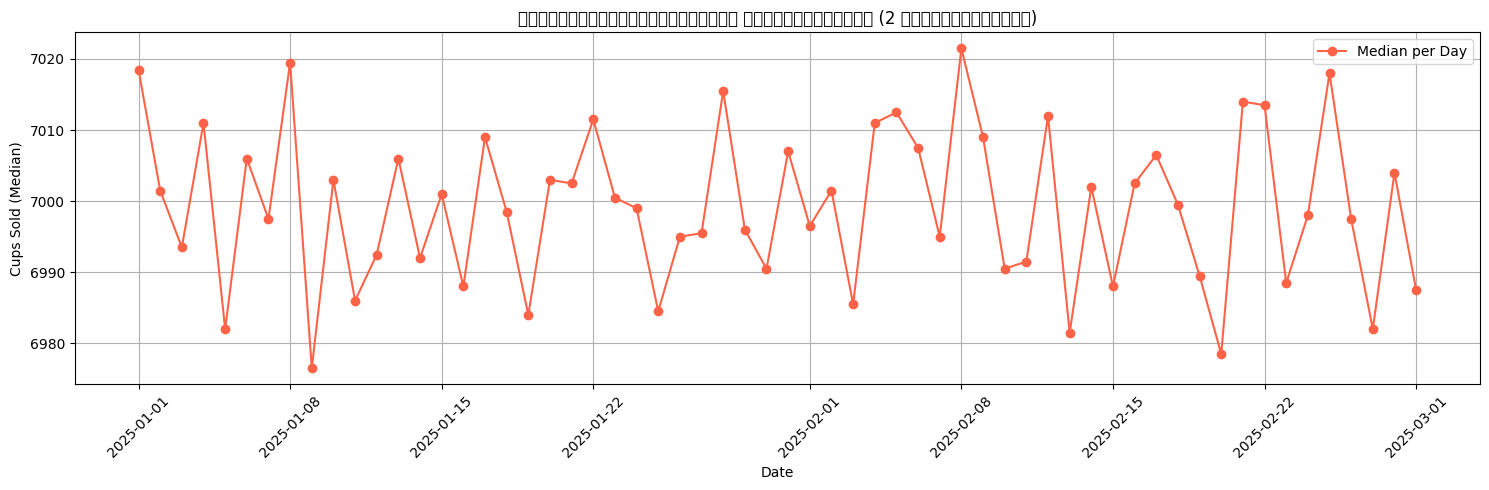

In [93]:
for date, median_val in zip(forecast_dates, median_per_day):
    print(f"{date.date()}: มัธยฐาน ≈ {median_val:.0f} แก้ว")

# --- วาดกราฟมัธยฐานต่อวัน ---
plt.figure(figsize=(15,5))
plt.plot(forecast_dates, median_per_day, color="tomato", marker="o", label="Median per Day")
plt.title("ค่ามัธยฐานยอดขายต่อวัน แสดงจำนวนแก้ว (2 เดือนข้างหน้า)")
plt.xlabel("Date")
plt.ylabel("Cups Sold (Median)")
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()
